In [1]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator
import os
import sys

# Pfade zur Logik (mapping.py liegt einen Ordner höher in /scripts)
sys.path.append(os.path.abspath('..'))
from src.mapping import SHIP_MAPPING, CAT_COLORS

print("Setup abgeschlossen. Bibliotheken und Mapping geladen.")


Setup abgeschlossen. Bibliotheken und Mapping geladen.


In [2]:
model_path = '../models/final_weights/v2_3classes_best.pt'
model = YOLO(model_path)
print(f"V2-Modell geladen: {model_path}")

V2-Modell geladen: ../models/final_weights/v2_3classes_best.pt


In [3]:
def analyze_and_plot_image(image_path, model, conf=0.6):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Fehler: Bild '{image_path}' konnte nicht geladen werden.")
        return
    
    results = model.predict(source=image_path, conf=conf, iou=0.9, verbose=False)

    annotator = Annotator(img.copy(), line_width=1)

    stats = {cat: 0 for cat in SHIP_MAPPING.keys()}
    stats['Unknown'] = 0

    for r in results:
        for box in r.boxes:
            cls_id = int(box.cls[0])
            label = model.names[cls_id]
            conf_val = float(box.conf[0])
            coords = box.xyxy[0]

            category = "Unknown"
            label_str = str(label).lower()
            
            for cat, classes in SHIP_MAPPING.items():
                # Erkennt Hauptkategorie ODER alten Untertyp
                if label_str == cat.lower() or \
                   (label_str == "civilian" and cat == "Civilian/Other") or \
                   label in classes:
                    category = cat
                    break

            stats[category] += 1
            color = CAT_COLORS.get(category, (128, 128, 128))
            annotator.box_label(coords, f"{category} {conf_val:.2f}", color=color, txt_color=(255, 255, 255))

    return annotator.result(), stats



Analysiere Szenario: Militärische Überwachung: San Diego Base
Änderungen in der Schiffspräsenz:
 Alarm: 7x Military hinzugekommen.


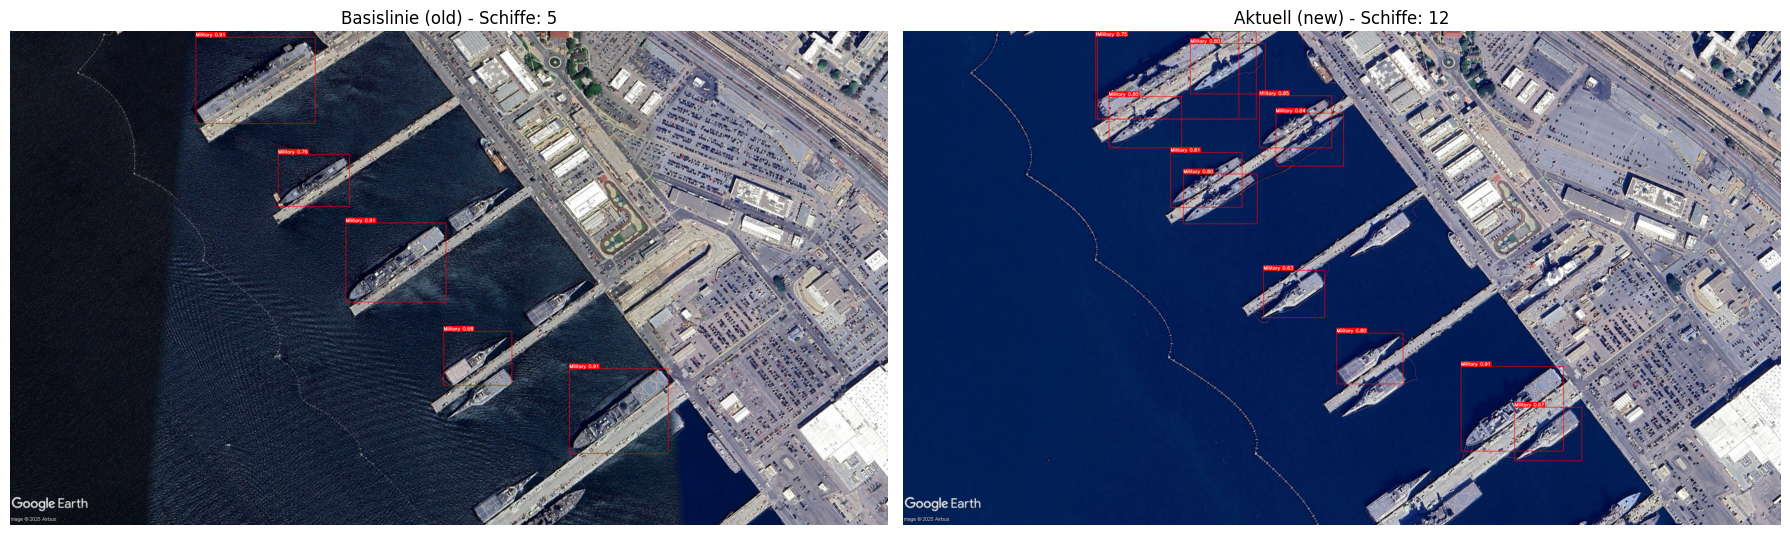


Analysiere Szenario: Logistik-Tracking: Hafen Hamburg
Änderungen in der Schiffspräsenz:
 Alarm: 1x Military hinzugekommen.
 Alarm: 3x Logistics hinzugekommen.
 Alarm: 1x Civilian/Other hinzugekommen.


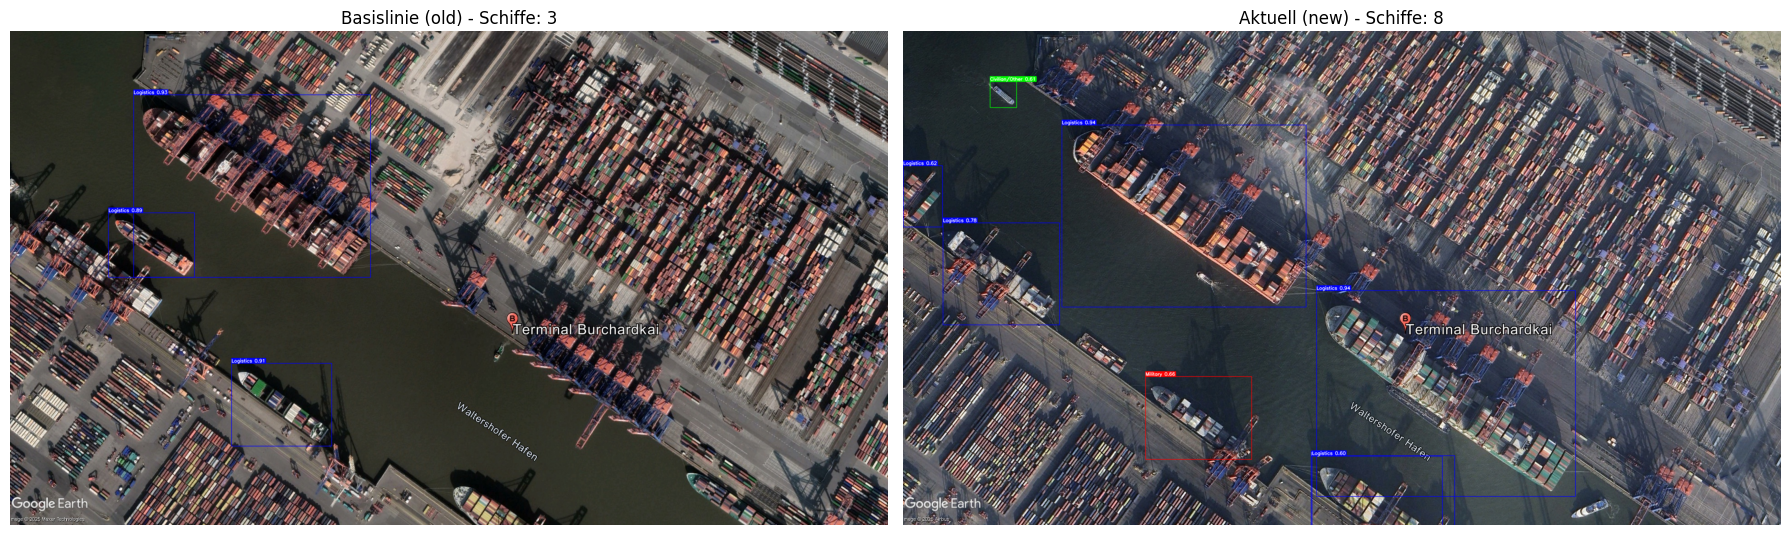

In [4]:
scenarios = {
    "military_san_diego": {
        "titel": "Militärische Überwachung: San Diego Base",
        "old": '../data/processed/ship_data/test/images/military_old.jpg',
        "new": '../data/processed/ship_data/test/images/military_new.jpg'
    },
    "logistic_hamburg": {
        "titel": "Logistik-Tracking: Hafen Hamburg",
        "old": '../data/processed/ship_data/test/images/logistics_old.jpg',
        "new": '../data/processed/ship_data/test/images/logistics_new.jpg'
    }
}

for key, scenario in scenarios.items():
    print(f"\nAnalysiere Szenario: {scenario['titel']}")

    #Analyse der beiden Zeitpunkte
    res_old, stats_old = analyze_and_plot_image(scenario['old'], model)
    res_new, stats_new = analyze_and_plot_image(scenario['new'], model)

    #Protokollierung der Änderungen
    print("Änderungen in der Schiffspräsenz:")
    found_changes = False
    for cat in SHIP_MAPPING.keys():
        diff = stats_new[cat] - stats_old[cat]
        if diff > 0:
            print(f" Alarm: {diff}x {cat} hinzugekommen.")
            found_changes = True
        elif diff < 0:
            print(f" Alarm: {-diff}x {cat} verschwunden.")
            found_changes = True
    if not found_changes:
        print(" Keine signifikanten Änderungen festgestellt.")
    
    #Visualisierung der Ergebnisse
    fig, axs = plt.subplots(1, 2, figsize=(18, 8))
    axs[0].imshow(cv2.cvtColor(res_old, cv2.COLOR_BGR2RGB))
    axs[0].set_title(f"Basislinie (old) - Schiffe: {sum(stats_old.values())}")
    axs[0].axis('off')

    axs[1].imshow(cv2.cvtColor(res_new, cv2.COLOR_BGR2RGB))
    axs[1].set_title(f"Aktuell (new) - Schiffe: {sum(stats_new.values())}")
    axs[1].axis('off')

    plt.tight_layout()
    plt.show()

STARTE BATCH-ANALYSE: 7 Bilder gefunden
Negativ: Keine Schiffe gefunden in 'test_coast.jpg'
Negativ: Keine Schiffe gefunden in 'test_empty_sea.jpg'
Treffer: Schiffe gefunden in 'test_marina.jpg' (7 Objekte erkannt) -> Generiere Visualisierung...


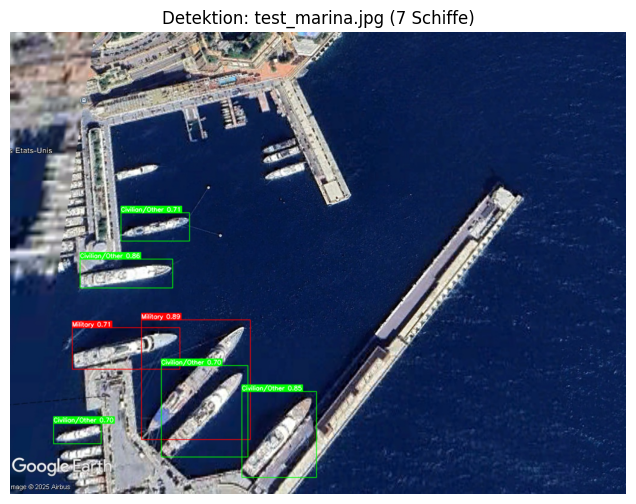

Treffer: Schiffe gefunden in 'test_marina2.jpg' (32 Objekte erkannt) -> Generiere Visualisierung...


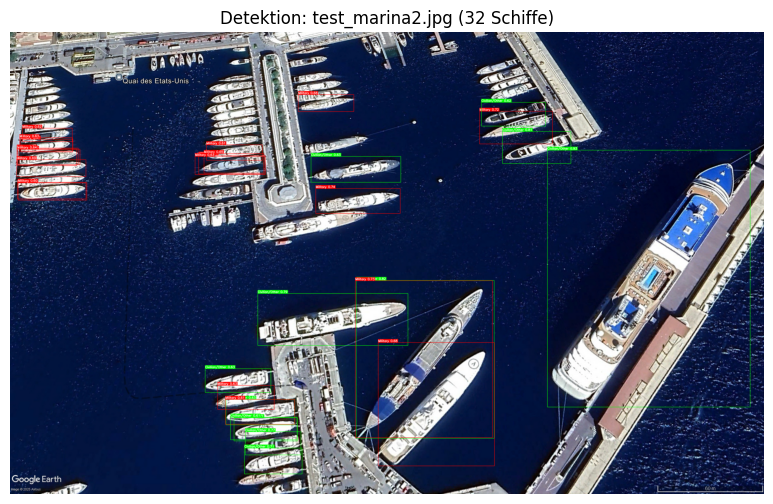

Treffer: Schiffe gefunden in 'test_shanghai.jpg' (5 Objekte erkannt) -> Generiere Visualisierung...


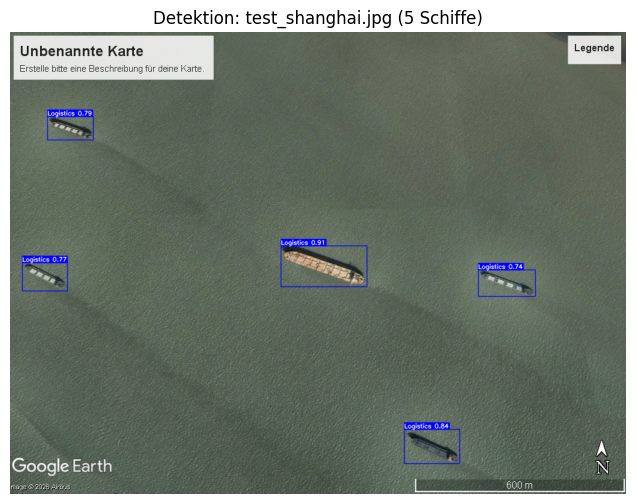

Treffer: Schiffe gefunden in 'test_singapur.jpg' (6 Objekte erkannt) -> Generiere Visualisierung...


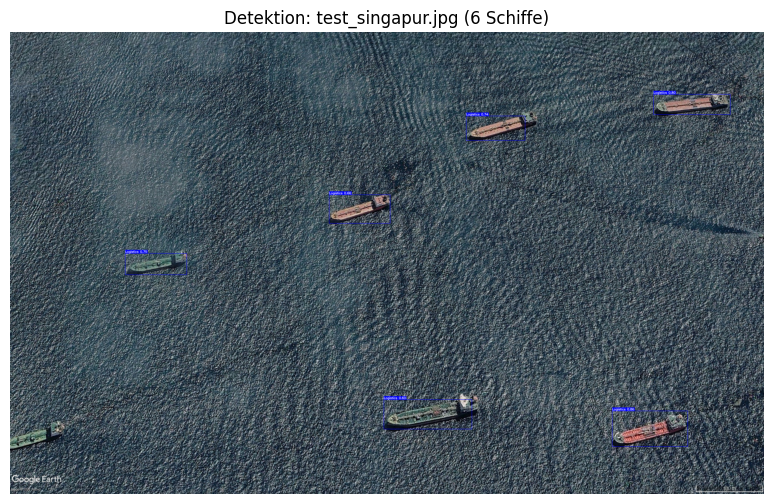

Treffer: Schiffe gefunden in 'test_suez.jpg' (1 Objekte erkannt) -> Generiere Visualisierung...


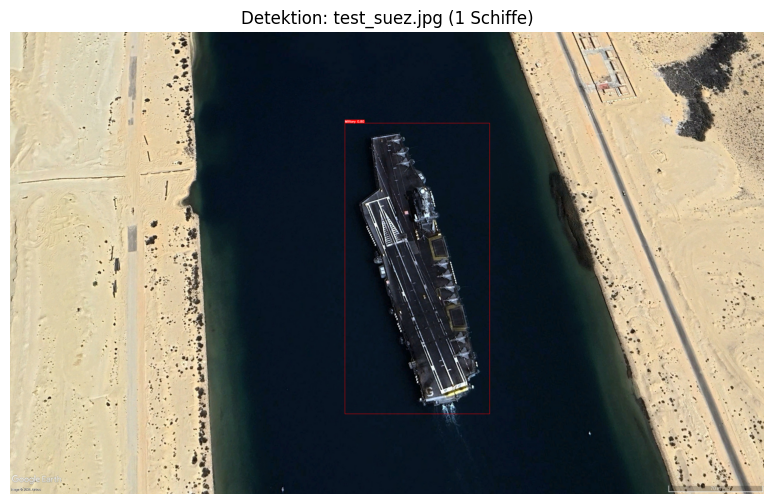


BATCH-SCREENING ERGEBNISBERICHT
Analysierte Bilder insgesamt: 7
Bilder mit Detektionen:       5
Bilder ohne Detektionen:      2
--------------------------------------------------
Detaillierte Trefferliste:
 -> test_marina.jpg: 7 Schiffe erkannt
 -> test_marina2.jpg: 32 Schiffe erkannt
 -> test_shanghai.jpg: 5 Schiffe erkannt
 -> test_singapur.jpg: 6 Schiffe erkannt
 -> test_suez.jpg: 1 Schiffe erkannt


In [18]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator

# --- KONFIGURATION ---
BATCH_FOLDER = '../data/processed/ship_data/test/batch_screening'
CONFIDENCE_THRESHOLD = 0.6

# Sicherstellen, dass der Ordner existiert
if not os.path.exists(BATCH_FOLDER):
    os.makedirs(BATCH_FOLDER)
    print(f"Hinweis: Der Ordner '{BATCH_FOLDER}' wurde frisch erstellt. Bitte lade dort Testbilder hoch.")

# Suche nach allen gängigen Bildformaten im Zielordner
extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
images_to_scan = []
for ext in extensions:
    images_to_scan.extend(glob.glob(os.path.join(BATCH_FOLDER, ext)))

images_to_scan = list(set(images_to_scan))  # Duplikate entfernen, falls vorhanden
images_to_scan.sort()  #  Sortieren der Bilder nach Namen

print("==================================================")
print(f"STARTE BATCH-ANALYSE: {len(images_to_scan)} Bilder gefunden")
print("==================================================")

# Listen für die finale Auswertung
bilder_mit_schiffen = []
bilder_ohne_schiffe = []

# Sequenzielle Inferenz über alle gefundenen Bilder
for img_path in images_to_scan:
    filename = os.path.basename(img_path)
    
    # Bild mit OpenCV laden
    img = cv2.imread(img_path)
    if img is None:
        print(f"Fehler: Bild '{filename}' konnte nicht geladen werden.")
        continue
        
    # Inferenz durchführen
    results = model.predict(source=img_path, conf=CONFIDENCE_THRESHOLD, iou=0.9, verbose=False)
    
    # Annotator initialisieren
    annotator = Annotator(img.copy(), line_width=1)
    
    total_detected_ships = 0
    
    # 1. SCHLEIFE: Alle Boxen auf dem aktuellen Bild sammeln und zeichnen
    for r in results:
        for box in r.boxes:
            total_detected_ships += 1
            
            # Extraktion der YOLO-Informationen
            cls_id = int(box.cls[0])
            label = model.names[cls_id]
            conf_val = float(box.conf[0])
            coords = box.xyxy[0]

            # Mapping-Logik
            category = "Unknown"
            label_str = str(label).lower()
            
            for cat, classes in SHIP_MAPPING.items():
                if label_str == cat.lower() or \
                   (label_str == "civilian" and cat == "Civilian/Other") or \
                   label in classes:
                    category = cat
                    break

            # Farbe bestimmen und Box zeichnen
            color = CAT_COLORS.get(category, (128, 128, 128))
            annotator.box_label(coords, f"{category} {conf_val:.2f}", color=color, txt_color=(255, 255, 255))
    
    # 2. ENTSCHEIDUNG: Erst NACHDEM alle Boxen gezeichnet wurden, wird das Bild ausgegeben
    if total_detected_ships > 0:
        print(f"Treffer: Schiffe gefunden in '{filename}' ({total_detected_ships} Objekte erkannt) -> Generiere Visualisierung...")
        bilder_mit_schiffen.append((filename, total_detected_ships))
        
        # Das fertig gezeichnete Bild extrahieren
        res_img = annotator.result()
        im_rgb = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
        
        # Bild genau EINMAL anzeigen
        plt.figure(figsize=(10, 6))
        plt.imshow(im_rgb)
        plt.title(f"Detektion: {filename} ({total_detected_ships} Schiffe)")
        plt.axis('off')
        plt.show()
        
            
    else:
        print(f"Negativ: Keine Schiffe gefunden in '{filename}'")
        bilder_ohne_schiffe.append(filename)

# ==================================================
# FINALE ZUSAMMENFASSUNG
# ==================================================
print("\n==================================================")
print("BATCH-SCREENING ERGEBNISBERICHT")
print("==================================================")
print(f"Analysierte Bilder insgesamt: {len(images_to_scan)}")
print(f"Bilder mit Detektionen:       {len(bilder_mit_schiffen)}")
print(f"Bilder ohne Detektionen:      {len(bilder_ohne_schiffe)}")
print("--------------------------------------------------")

if len(bilder_mit_schiffen) > 0:
    print("Detaillierte Trefferliste:")
    for name, count in bilder_mit_schiffen:
        print(f" -> {name}: {count} Schiffe erkannt")
else:
    print("Keine Schiffe auf den analysierten Bildern gefunden.")
print("==================================================")
